In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
    auc
)

In [7]:
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


In [8]:
np.random.seed(42)
torch.manual_seed(42)

In [9]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: cpu


In [10]:
#loading the data

df = pd.read_csv('/content/breast_cancer_data (2).csv')

In [11]:
df.shape

(569, 33)

In [12]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [13]:
df= df.drop(columns=["id","Unnamed: 32"])

In [14]:
df["diagnosis"] = df["diagnosis"].map({"M":1,"B":0}).astype(int)

In [15]:
class_names = ["benign", "malignant"]

In [16]:
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [17]:
df["diagnosis"].value_counts(normalize=True)

,proportion
diagnosis,
0,0.627417
1,0.372583


In [18]:
df[["radius_mean", "area_mean", "smoothness_mean"]].describe()

,radius_mean,area_mean,smoothness_mean
count,569.000000,569.000000,569.000000
mean,14.127292,654.889104,0.096360
std,3.524049,351.914129,0.014064
min,6.981000,143.500000,0.052630
25%,11.700000,420.300000,0.086370
50%,13.370000,551.100000,0.095870
75%,15.780000,782.700000,0.105300
max,28.110000,2501.000000,0.163400


In [19]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

In [20]:

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=42
)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)

Train: (341, 30)
Val:   (114, 30)
Test:  (114, 30)


In [21]:
X_test_raw = X_test.copy()


In [22]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [23]:
#Converting numpy arrays to tesors
# create the tensors and move them to the device
X_train_t = torch.tensor(X_train, dtype=torch.float32).to(device)
X_val_t   = torch.tensor(X_val, dtype=torch.float32).to(device)
X_test_t  = torch.tensor(X_test, dtype=torch.float32).to(device)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1).to(device)
y_val_t   = torch.tensor(y_val.values, dtype=torch.float32).unsqueeze(1).to(device)
y_test_t  = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1).to(device)

print("X_train_t:", X_train_t.shape, "y_train_t:", y_train_t.shape)
print("On device:", X_train_t.device)

X_train_t: torch.Size([341, 30]) y_train_t: torch.Size([341, 1])
On device: cpu


In [24]:
train_ds = TensorDataset(X_train_t, y_train_t)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

print("Batches per epoch:", len(train_loader))

Batches per epoch: 11


In [25]:
class BreastCanceNet(nn.Module):
  def __init__(self,num_features=30):
    super().__init__()

    self.layer1 = nn.Linear(num_features,16)
    self.layer2 = nn.Linear(16,8)
    self.output = nn.Linear(8,1)

    #activation functions
    self.relu = nn.ReLU()
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    x = self.relu(self.layer1(x))
    x= self.relu(self.layer2(x))
    x=self.sigmoid(self.output(x))


    return x



In [26]:
model = BreastCanceNet(num_features=X_train_t.shape[1])

In [27]:
model

BreastCanceNet(
  (layer1): Linear(in_features=30, out_features=16, bias=True)
  (layer2): Linear(in_features=16, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=1, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)

In [28]:
loss_function = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


In [29]:
def accuracy(y_prob, y_true):
  y_pred =(y_prob > 0.5).float()
  return (y_pred == y_true).float().mean().item()

In [30]:
#training

In [31]:
epochs = 30
history ={
    "loss" : [],
    "accuracy": [],
    "val_loss" : [],
    "val_accuracy" :[]
}

for epoch in range(epochs):

  #training
  model.train()
  for X_batch, y_batch in train_loader:
    y_prob = model(X_batch)
    loss = loss_function(y_prob, y_batch)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()



  #evaluation
  model.eval()
  with torch.no_grad():
    train_prob = model(X_train_t)
    val_prob = model(X_val_t)

    train_loss = loss_function(train_prob, y_train_t)
    val_loss = loss_function(val_prob, y_val_t)

    train_acc = accuracy(train_prob, y_train_t)
    val_acc = accuracy(val_prob, y_val_t)

  history["loss"].append(train_loss)
  history["accuracy"].append(train_acc)
  history["val_loss"].append(val_loss)
  history["val_accuracy"].append(val_acc)

  print(f"epoch {epoch + 1:3d}  "
        f"loss {train_loss:.4f}  acc {history['accuracy'][-1]:.4f}  "
        f"val_loss {val_loss:.4f}  val_acc {history['val_accuracy'][-1]:.4f}")


epoch   1  loss 0.6745  acc 0.7097  val_loss 0.6773  val_acc 0.7544
epoch   2  loss 0.6493  acc 0.8328  val_loss 0.6545  val_acc 0.8333
epoch   3  loss 0.6193  acc 0.8680  val_loss 0.6272  val_acc 0.8596
epoch   4  loss 0.5841  acc 0.8768  val_loss 0.5951  val_acc 0.8947
epoch   5  loss 0.5443  acc 0.8886  val_loss 0.5583  val_acc 0.9123
epoch   6  loss 0.5003  acc 0.9062  val_loss 0.5164  val_acc 0.9211
epoch   7  loss 0.4526  acc 0.9150  val_loss 0.4703  val_acc 0.9211
epoch   8  loss 0.4011  acc 0.9179  val_loss 0.4193  val_acc 0.9211
epoch   9  loss 0.3512  acc 0.9179  val_loss 0.3700  val_acc 0.9211
epoch  10  loss 0.3075  acc 0.9238  val_loss 0.3273  val_acc 0.9386
epoch  11  loss 0.2698  acc 0.9326  val_loss 0.2901  val_acc 0.9386
epoch  12  loss 0.2387  acc 0.9355  val_loss 0.2591  val_acc 0.9474
epoch  13  loss 0.2126  acc 0.9443  val_loss 0.2322  val_acc 0.9474
epoch  14  loss 0.1911  acc 0.9472  val_loss 0.2082  val_acc 0.9474
epoch  15  loss 0.1732  acc 0.9531  val_loss 0.1

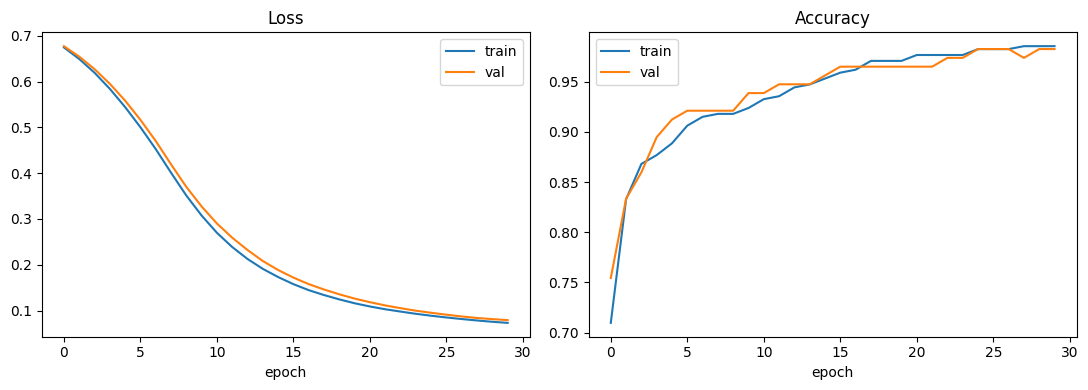

In [32]:
#learning curves
hist = history

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(hist["loss"], label="train")
plt.plot(hist["val_loss"], label="val")
plt.title("Loss"); plt.xlabel("epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist["accuracy"], label="train")
plt.plot(hist["val_accuracy"], label="val")
plt.title("Accuracy"); plt.xlabel("epoch"); plt.legend()

plt.tight_layout()
plt.show()

In [34]:
#evaluating on the test set
model.eval()
with torch.no_grad():
    test_prob = model(X_test_t)
    test_loss = loss_function(test_prob, y_test_t).item()
    test_acc = accuracy(test_prob, y_test_t)

print("Test loss:", round(test_loss, 3))
print("Test accuracy:", round(test_acc, 3))


Test loss: 0.074
Test accuracy: 0.991


In [35]:
y_prob = test_prob.cpu().numpy().ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("First 5 probabilities:", y_prob[:5].round(3))
print("First 5 predictions:  ", y_pred[:5])

First 5 probabilities: [0.001 1.    0.133 0.715 0.384]
First 5 predictions:   [0 1 0 1 0]


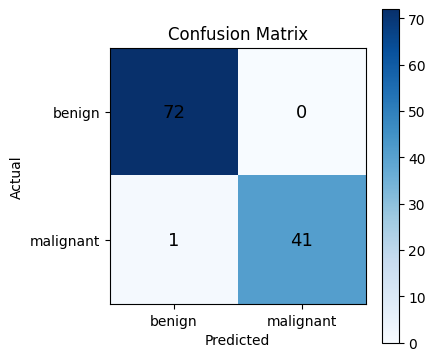

In [36]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.xticks([0, 1], ["benign", "malignant"])
plt.yticks([0, 1], ["benign", "malignant"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=13)
plt.colorbar()
plt.tight_layout()
plt.show()

In [37]:
print(classification_report(y_test, y_pred, target_names = class_names))

              precision    recall  f1-score   support

      benign       0.99      1.00      0.99        72
   malignant       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114

